In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import yfinance as yf


In [25]:
print('Loading cryptocurrency data...')
df = pd.read_csv('CryptocurrencyData.csv')

Loading cryptocurrency data...


In [26]:
print('\n1. Basic Dataset Information:')
print('-' * 50)
print(f'Number of cryptocurrencies: {len(df)}')
print(f'Number of features: {len(df.columns)}')
print('\nFeatures in the dataset:', ', '.join(df.columns))


1. Basic Dataset Information:
--------------------------------------------------
Number of cryptocurrencies: 4150
Number of features: 12

Features in the dataset: Rank, Coin Name, Symbol,  Price , 1h, 24h, 7d, 30d,  24h Volume , Circulating Supply, Total Supply,  Market Cap 


In [27]:
print('Top 5 Cryptocurrencies:')
print('-' * 50)
print(df[['Rank', 'Coin Name', 'Symbol', ' Price ', ' Market Cap ']].head())

Top 5 Cryptocurrencies:
--------------------------------------------------
   Rank Coin Name Symbol     Price            Market Cap 
0     1   Bitcoin    BTC  36,456.94  $712,726,163,003.00 
1     2  Ethereum    ETH   2,027.60  $243,488,187,281.00 
2     3    Tether   USDT       1.00   $88,027,617,310.00 
3     4       BNB    BNB     231.63   $35,716,332,862.00 
4     5       XRP    XRP       0.59   $31,863,926,051.00 


In [28]:
def clean_price(price_str):
    if isinstance(price_str, str):
        # Remove $ and commas
        price_str = price_str.replace('$', '').replace(',', '')
        try:
            return float(price_str)
        except:
            return 0
    return 0


df['Clean_Price'] = df[' Price '].apply(clean_price)

print('Price Statistics (in USD):')
print('-' * 50)
price_stats = df['Clean_Price'].describe()
print(f'Average Price: ${price_stats["mean"]:.2f}')
print(f'Minimum Price: ${price_stats["min"]:.2f}')
print(f'Maximum Price: ${price_stats["max"]:.2f}')



Price Statistics (in USD):
--------------------------------------------------
Average Price: $176.40
Minimum Price: $0.00
Maximum Price: $109861.00


In [29]:
price_ranges = [0, 1, 10, 100, 1000, float('inf')]
labels = ['$0-$1', '$1-$10', '$10-$100', '$100-$1000', 'Over $1000']
df['Price_Range'] = pd.cut(df['Clean_Price'], bins=price_ranges, labels=labels)
price_distribution = df['Price_Range'].value_counts().sort_index()

print('Price Distribution:')
print('-' * 50)
print(price_distribution)


Price Distribution:
--------------------------------------------------
Price_Range
$0-$1         1939
$1-$10         291
$10-$100       117
$100-$1000      34
Over $1000      43
Name: count, dtype: int64


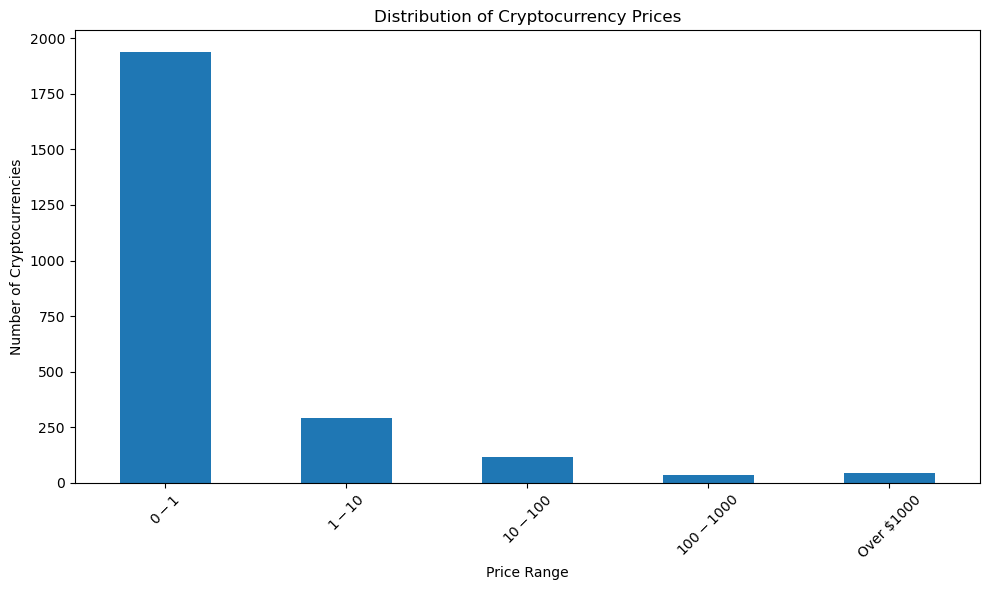

In [30]:
plt.figure(figsize=(10, 6))
price_distribution.plot(kind='bar')
plt.title('Distribution of Cryptocurrency Prices')
plt.xlabel('Price Range')
plt.ylabel('Number of Cryptocurrencies')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [31]:
print('Missing Data Analysis:')
print('-' * 50)
missing_data = df.isnull().sum()
if missing_data.sum() > 0:
    print('\nColumns with missing values:')
    print(missing_data[missing_data > 0])
else:
    print('No missing values found in the dataset!')



Missing Data Analysis:
--------------------------------------------------

Columns with missing values:
1h               95
7d                2
30d              57
Price_Range    1726
dtype: int64


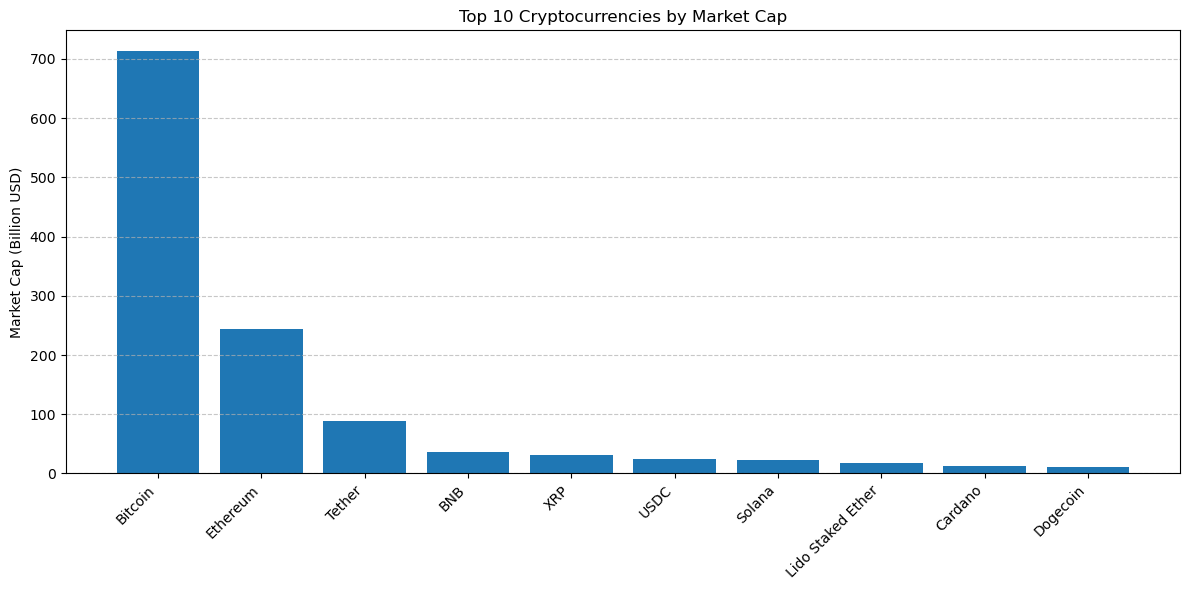


Top 10 Cryptocurrencies by Market Cap:
--------------------------------------------------
Bitcoin: $712.73 Billion
Ethereum: $243.49 Billion
Tether: $88.03 Billion
BNB: $35.72 Billion
XRP: $31.86 Billion
USDC: $24.12 Billion
Solana: $23.26 Billion
Lido Staked Ether: $18.44 Billion
Cardano: $12.90 Billion
Dogecoin: $10.53 Billion


In [32]:

def clean_market_cap(value):
    if isinstance(value, str):
        value = value.replace('$', '').replace(' ', '').replace(',', '')
        try:
            return float(value)
        except:
            return 0
    return 0

df['Clean_Market_Cap'] = df[' Market Cap '].apply(clean_market_cap)

top_10_by_market_cap = df.nlargest(10, 'Clean_Market_Cap')

plt.figure(figsize=(12, 6))
plt.bar(top_10_by_market_cap['Coin Name'], top_10_by_market_cap['Clean_Market_Cap'] / 1e9)  # Convert to billions
plt.title('Top 10 Cryptocurrencies by Market Cap')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Market Cap (Billion USD)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("\nTop 10 Cryptocurrencies by Market Cap:")
print("-" * 50)
for _, row in top_10_by_market_cap.iterrows():
    print(f"{row['Coin Name']}: ${row['Clean_Market_Cap']/1e9:.2f} Billion")


3. Cryptocurrency Correlation Analysis:
--------------------------------------------------


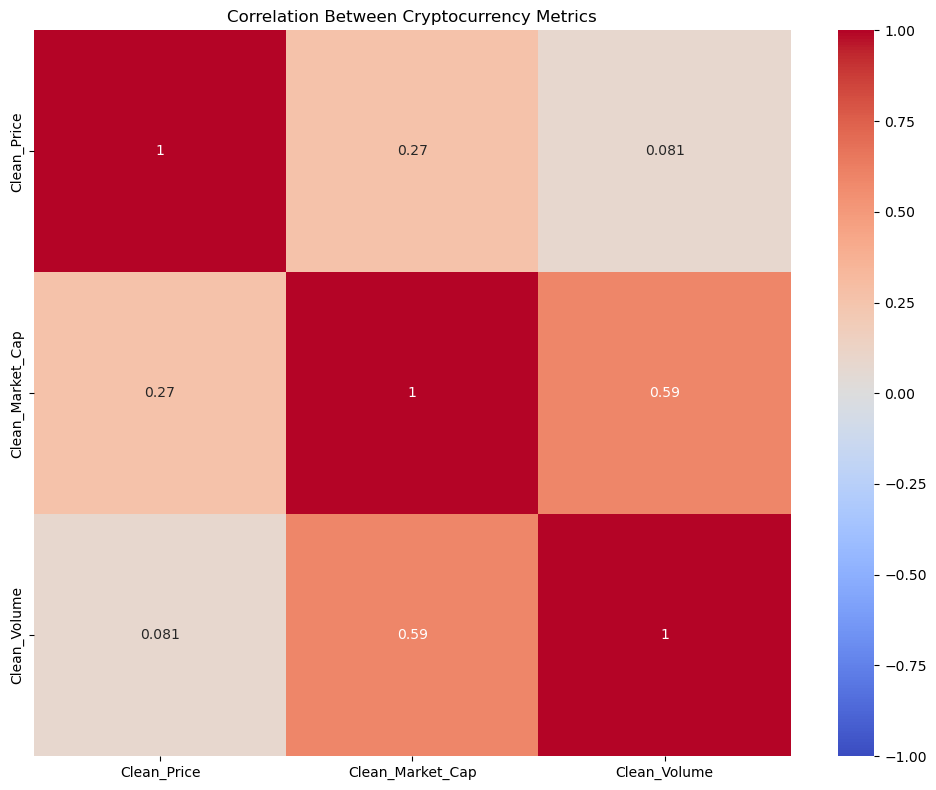

In [33]:


print('\n3. Cryptocurrency Correlation Analysis:')
print('-' * 50)

def clean_numeric(x):
    if pd.isna(x) or str(x).strip() in ['-', ' -   ', '']:
        return np.nan
    try:
        return float(str(x).replace('$', '').replace(',', '').strip())
    except (ValueError, TypeError):
        return np.nan

df['Clean_Price'] = df[' Price '].apply(clean_numeric)
df['Clean_Market_Cap'] = df[' Market Cap '].apply(clean_numeric)
df['Clean_Volume'] = df[' 24h Volume '].apply(clean_numeric)

corr_data = df[['Clean_Price', 'Clean_Market_Cap', 'Clean_Volume']]
corr_matrix = corr_data.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation Between Cryptocurrency Metrics')
plt.tight_layout()
plt.show()

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


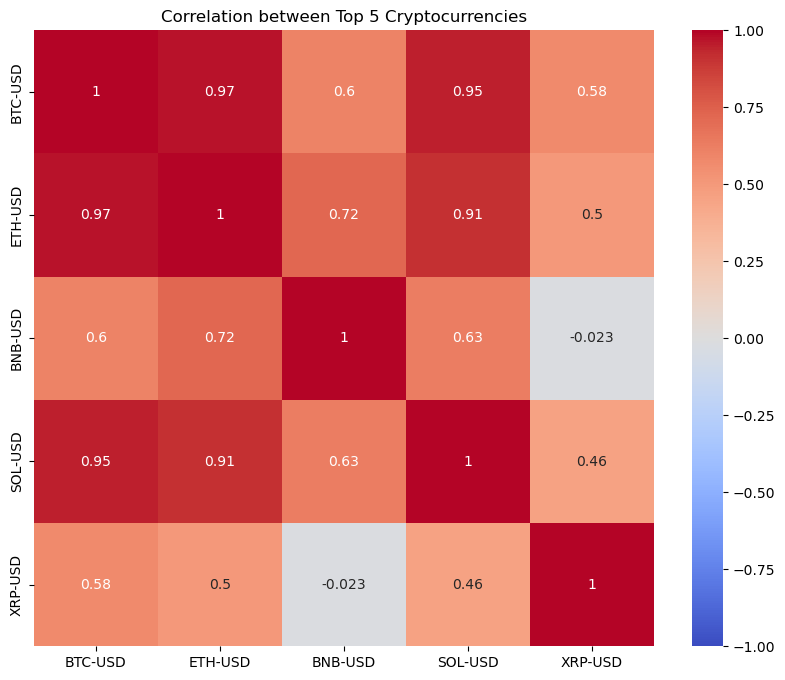

In [34]:

cryptos = ['BTC-USD', 'ETH-USD', 'BNB-USD', 'SOL-USD', 'XRP-USD']
crypto_data = pd.DataFrame()

for crypto in cryptos:
    data = yf.download(crypto, start='2023-01-01', end='2024-03-20')['Close']
    crypto_data[crypto] = data

correlation = crypto_data.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation, 
            annot=True, 
            cmap='coolwarm', 
            vmin=-1, 
            vmax=1, 
            center=0)
plt.title('Correlation between Top 5 Cryptocurrencies')
plt.show()